# Utilities

## Libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import re, string, Levenshtein, joblib
import numpy as np

from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualization
from wordcloud import WordCloud

## Functions

In [4]:
# For index_terms treatment, list_flatten and dict_flatten are defined.

def list_flatten(my_list):

    result = []

    # Iterate over my_list
    for element in my_list:

        # If it is a list, unpack and append to result
        if isinstance(element, list):
            result.extend(list_flatten(element))

        # If it is a string
        elif isinstance(element, str):
            element = element.strip() # Remove start/end spaces
            result.append(element)    # Append to result
        
        # Else raise error
        else:
            raise TypeError('Element is not list or string.')

    return result

def dict_flatten(my_dict):
    
    result = []

    # Iterate over my_dict
    for key, val in my_dict.items():

        # If it is a dictionary, unpack and append to result
        if isinstance(val, dict):
            result.extend(dict_flatten(val))
        
        # If it is a list, unpack and append to result
        elif isinstance(val, list):
            result.extend(val)        
        
        # Else raise error
        else:
            raise TypeError('Element is not dictionary or list')
    
    return result

# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text, save_figure):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    if save_figure:
        plt.savefig(f'../data/output/{save_figure}.pdf')
    plt.show()

# Data formatting

In [5]:
# Load data
data = pd.read_csv('../data/input/api/data.csv')
display(data.shape)
display(data.head())

(6744, 7)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
0,0,$\beta$-Ga2O3 in Power Electronics Converters:...,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410,"In this work, the possibility of using differe...",7,https://ieeexplore.ieee.org/document/10496151/
1,0,(2N+1) Selective Harmonic Elimination-PWM for ...,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209,The performance of modular multilevel converte...,75,https://ieeexplore.ieee.org/document/7849220/
2,0,1-MW Full-Bridge MMC for High-Current Low-Volt...,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826,A full-bridge modular multilevel converter (MM...,0,https://ieeexplore.ieee.org/document/9178138/
3,0,1-kV Input 1-MHz GaN Modular Multilevel LLC Co...,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527,A modular multilevel LLC converter suitable fo...,3,https://ieeexplore.ieee.org/document/8721944/
4,0,"1.5-kV, 1.5-kW, High Voltage Ratio, Bidirectio...",{'ieee_terms': {'terms': ['Multilevel converte...,20250210,Modular multilevel GaN-based isolated DC/DC co...,0,https://ieeexplore.ieee.org/document/10861671/


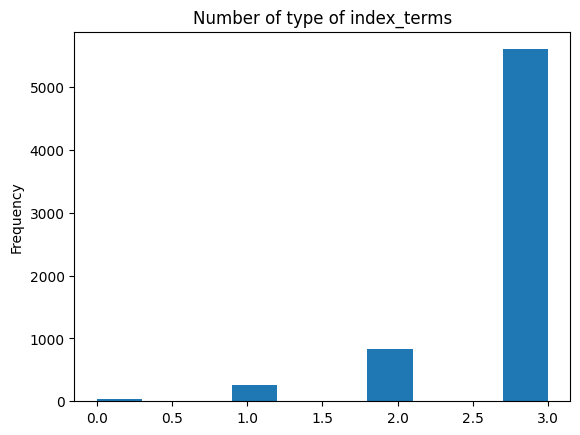

In [6]:
# Count number of type of index_terms
list_terms = [len(eval(dic_index_term).keys()) for dic_index_term in data['index_terms'].values]

plt.figure()
plt.hist(list_terms)
plt.title('Number of type of index_terms')
plt.ylabel('Frequency')
plt.show()

In [7]:
# Sample index_terms value
sample = data.iloc[0]['index_terms']

In [8]:
# The solution is to append all terms to a flat list
dic_terms = eval(sample)
dic_terms

{'ieee_terms': {'terms': ['Schottky diodes',
   'Costs',
   'Performance evaluation',
   'Diamonds',
   'Silicon carbide',
   'Power electronics',
   'Thermal conductivity']},
 'author_terms': {'terms': ['  $\\beta$  -Ga  $_2$  0  $_3$  ',
   'diamond',
   'gallium oxide',
   'HVDC converters',
   'ultra-wide-bandgap']},
 'dynamic_index_terms': {'terms': ['Power Electronics',
   'Power Electronic Converters',
   'High Power',
   'Temperature Rise',
   'Incumbent',
   'Re-election',
   'Device Applications',
   'Power Loss',
   'Thermal Resistance',
   'Power Conversion',
   'Computer-aided Design',
   'Power Devices',
   'Power Transistors',
   'Power Semiconductor Devices',
   'Semiconductor Devices',
   'Converter Operation',
   'Performance Of Converter',
   'Power Semiconductor',
   'Modular Multilevel Converter',
   'On-state Resistance',
   'Blocking Voltage',
   'High Voltage',
   'Higher Tendency',
   'Thermal Conductivity',
   'Heat Conduction',
   'Power System',
   'Si Devic

In [9]:
# Flatten dictionary
dict_flatten(dic_terms)

['Schottky diodes',
 'Costs',
 'Performance evaluation',
 'Diamonds',
 'Silicon carbide',
 'Power electronics',
 'Thermal conductivity',
 '  $\\beta$  -Ga  $_2$  0  $_3$  ',
 'diamond',
 'gallium oxide',
 'HVDC converters',
 'ultra-wide-bandgap',
 'Power Electronics',
 'Power Electronic Converters',
 'High Power',
 'Temperature Rise',
 'Incumbent',
 'Re-election',
 'Device Applications',
 'Power Loss',
 'Thermal Resistance',
 'Power Conversion',
 'Computer-aided Design',
 'Power Devices',
 'Power Transistors',
 'Power Semiconductor Devices',
 'Semiconductor Devices',
 'Converter Operation',
 'Performance Of Converter',
 'Power Semiconductor',
 'Modular Multilevel Converter',
 'On-state Resistance',
 'Blocking Voltage',
 'High Voltage',
 'Higher Tendency',
 'Thermal Conductivity',
 'Heat Conduction',
 'Power System',
 'Si Devices',
 'Power Sector',
 'Rated Power',
 'Converter Topology',
 'Switching Loss',
 'Schottky Diode',
 'Schottky Barrier Diodes',
 'Submodule',
 'Thermal Management'

In [10]:
# Flatten list
list_flatten(dict_flatten(dic_terms))

['Schottky diodes',
 'Costs',
 'Performance evaluation',
 'Diamonds',
 'Silicon carbide',
 'Power electronics',
 'Thermal conductivity',
 '$\\beta$  -Ga  $_2$  0  $_3$',
 'diamond',
 'gallium oxide',
 'HVDC converters',
 'ultra-wide-bandgap',
 'Power Electronics',
 'Power Electronic Converters',
 'High Power',
 'Temperature Rise',
 'Incumbent',
 'Re-election',
 'Device Applications',
 'Power Loss',
 'Thermal Resistance',
 'Power Conversion',
 'Computer-aided Design',
 'Power Devices',
 'Power Transistors',
 'Power Semiconductor Devices',
 'Semiconductor Devices',
 'Converter Operation',
 'Performance Of Converter',
 'Power Semiconductor',
 'Modular Multilevel Converter',
 'On-state Resistance',
 'Blocking Voltage',
 'High Voltage',
 'Higher Tendency',
 'Thermal Conductivity',
 'Heat Conduction',
 'Power System',
 'Si Devices',
 'Power Sector',
 'Rated Power',
 'Converter Topology',
 'Switching Loss',
 'Schottky Diode',
 'Schottky Barrier Diodes',
 'Submodule',
 'Thermal Management',
 '

In [11]:
# Flatten all data index_terms
data['index_terms'] = data['index_terms'].apply(eval).apply(dict_flatten).apply(list_flatten)
data['index_terms']

0       [Schottky diodes, Costs, Performance evaluatio...
1       [Switches, Harmonic analysis, Pulse width modu...
2       [Low Voltage, Modular Multilevel Converter, Fu...
3       [Silicon carbide, Inductors, HEMTs, MODFETs, S...
4       [Multilevel converters, Vacuum systems, Moon, ...
                              ...                        
6739    [Inductance, Capacitors, Zero current switchin...
6740    [Circuit faults, Voltage control, Grounding, D...
6741    [Reactive power, Multilevel converters, Capaci...
6742    [Power quality, Voltage fluctuations, Inductor...
6743                                                   []
Name: index_terms, Length: 6744, dtype: object

In [12]:
# Concatenate all index_terms for every row
data['index_terms'] = data['index_terms'].apply(lambda x: ' '.join(x))
data['index_terms']

0       Schottky diodes Costs Performance evaluation D...
1       Switches Harmonic analysis Pulse width modulat...
2       Low Voltage Modular Multilevel Converter Full-...
3       Silicon carbide Inductors HEMTs MODFETs Stress...
4       Multilevel converters Vacuum systems Moon Elem...
                              ...                        
6739    Inductance Capacitors Zero current switching S...
6740    Circuit faults Voltage control Grounding Distr...
6741    Reactive power Multilevel converters Capacitor...
6742    Power quality Voltage fluctuations Inductors V...
6743                                                     
Name: index_terms, Length: 6744, dtype: object

In [13]:
data.columns.tolist()

['citing_patent_count',
 'title',
 'index_terms',
 'insert_date',
 'abstract',
 'citing_paper_count',
 'html_url']

In [14]:
# Text columns
text_cols = [
    'title',
    'index_terms',
    'abstract'
]

# Numeric columns
numeric_cols = [
    'citing_patent_count',
    'insert_date',
    'citing_paper_count'
]

# Additional columns
additional_cols = ['html_url']

In [15]:
# Text columns to lower case and remove special characters (let numbers)
for col in text_cols:
    data[col] = data[col].str.lower()                                  # Lower case
    data[col] = data[col].str.replace(r'[^a-z0-9\s]', ' ', regex=True) # Remove spacial characters
    # data[col] = data[col].str.split(r'\s+')                            # Remove multiple spaces, convert to list (same as tokenization)
    data[col] = data[col].apply(word_tokenize)                         # Tokenization
    data[col] = data[col].apply(lambda x: ' '.join(x))                 # Convert back to string

data.head()

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
0,0,beta ga2o3 in power electronics converters opp...,schottky diodes costs performance evaluation d...,20240410,in this work the possibility of using differen...,7,https://ieeexplore.ieee.org/document/10496151/
1,0,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,20170209,the performance of modular multilevel converte...,75,https://ieeexplore.ieee.org/document/7849220/
2,0,1 mw full bridge mmc for high current low volt...,low voltage modular multilevel converter full ...,20200826,a full bridge modular multilevel converter mmc...,0,https://ieeexplore.ieee.org/document/9178138/
3,0,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,20190527,a modular multilevel llc converter suitable fo...,3,https://ieeexplore.ieee.org/document/8721944/
4,0,1 5 kv 1 5 kw high voltage ratio bidirectional...,multilevel converters vacuum systems moon elem...,20250210,modular multilevel gan based isolated dc dc co...,0,https://ieeexplore.ieee.org/document/10861671/


In [16]:
# Remove duplicated rows by abstract, keeping the one with greater citing_paper_count

col = 'abstract'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data = data.loc[data.groupby(col)['citing_paper_count'].idxmax()].copy()

print(len(data), data.duplicated(subset=[col], keep=False).sum())

6744 60
6713 0


In [17]:
# Remove duplicated rows by title, keeping the one with longest abstract
# The Levenshtein distance between abstracts of rows with duplicated title
# is relatively low, meaning they are similar (manual inspection).
# Having that into account, the criterion to keep rows is the one with largest abstract.

col = 'title'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data['abstract_length'] = data['abstract'].apply(len)
data = data.loc[data.groupby(col)['abstract_length'].idxmax()].copy()
data.drop(columns=['abstract_length'], inplace=True)

print(len(data), data.duplicated(subset=[col], keep=False).sum())

6713 157
6634 0


In [18]:
# # Levenshtein distance analysis of abstract of rows with repeated title

# col = 'title'

# mask = data.duplicated(subset=[col], keep=False)
# data_rep = data[mask].sort_values(by=['title', 'citing_paper_count'], ascending=[True, False]).copy()
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: sorted(x.split(' ')))
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: ' '.join(x))
# data_rep

# n = len(data_rep)
# distance_matrix = np.zeros((n, n))

# for i in range(n):
#     for j in range(n):
#         if i != j:
#             distance_matrix[i, j] = Levenshtein.distance(data_rep.iloc[i]['abstract'], data_rep.iloc[j]['abstract'])

In [19]:
# Identify data with suspicious title

col = 'title'

sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

['contents',
 'front cover',
 'mmc based sst',
 'control of mmcs',
 'dc transmission',
 'table of content',
 'best paper on rev',
 'table of contents',
 'meet the micro mmc',
 'main circuit design',
 'dynamics and control',
 'proceedings contents',
 'modeling and simulation',
 'design of capacitors in sst',
 'book reviews 7 books reviewed',
 'modular multilevel converters',
 'review of high power converters',
 'an optimized hybrid mmc for hvdc',
 'modular double cascade converter',
 'on the potential of igcts in hvdc',
 'review of mpc techniques for mmcs',
 'the multilevel modular dc converter',
 'control of mmcs under ac grid faults',
 'power reversal of hybrid hvdc system',
 'a novel multi modular series hvdc tap',
 'a t type modular multilevel converter',
 'electric drives for heavy duty trucks',
 'modeling of voltage source converters',
 'study of a state of the art m statcom',
 'mmc hvdc simulation and control system',
 'operating dc circuit breakers with mmc',
 'small signal mult

In [20]:
# Remove data with suspicious title

suspicious_titles = \
[
    'contents',
    'front cover',
    'table of content',
    'best paper on rev',
    'table of contents',
    'proceedings contents',
    'book reviews 7 books reviewed ',
]

mask = data['title'].isin(suspicious_titles)

display(data.loc[mask])

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
1957,0,best paper on rev,awards,20130530,g branda m coppola a dannier a del pizzo and d...,0,https://ieeexplore.ieee.org/document/6521511/
2397,0,contents,,20160815,the following topics are dealt with modular mu...,0,https://ieeexplore.ieee.org/document/7542979/
6743,0,front cover,,20130121,the following topics are dealt with power semi...,0,https://ieeexplore.ieee.org/document/6397374/
5560,0,proceedings contents,,20140619,the following topics are dealt with pm machine...,0,https://ieeexplore.ieee.org/document/6836772/
6349,0,table of content,rectifiers pulse width modulation voltage cont...,20170427,the following topics are dealt with matrix con...,0,https://ieeexplore.ieee.org/document/7910411/
6350,0,table of contents,,20171107,the following topics are dealt with power conv...,0,https://ieeexplore.ieee.org/document/8095748/


In [21]:
# Remove 
mask = data['title'] == 'best paper on rev'
data = data[~mask].copy()
data.shape

(6633, 7)

In [22]:
# Remove data with suspicious abstract

col = 'abstract'

sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

# It seems that there isn't suspicious abstracts

['this paper presents a loss calculation and comparison between different submodule topologies and semiconductor choices for a modular multilevel converter in a 1 1gw 320kv hvdc application',
 'a detailed analysis of the behaviour of a modular multilevel converter mmc in a hvdc system in case of both dc and ac faults is provided results related to a two terminal hvdc system are presented',
 'the articles in this special issue focus on the latest achievements of modular multilevel converters regarding the development of new circuit configurations converter models modulation strategies and control schemes',
 'in this paper an igbt half bridge with a parallel presspack diode for increased efficiency is investigated the switching performance and its losses are discussed with respect to its operation in a modular multilevel converter',
 'presents corrections to the paper a switched capacitor submodule for modular multilevel hvdc converters with dc fault blocking capability and a reduced num

In [23]:
# Filter abstracts using keywords

# M2C
m2c_keywords = 'mmc m2c modular multilevel converter'.split(' ')
m2c_keywords = '|'.join(m2c_keywords)
mask_m2c = data['abstract'].str.contains(m2c_keywords)

# M3C
m3c_keywords = 'mmmc m3c modular multilevel matrix converter'.split(' ')
m3c_keywords = '|'.join(m3c_keywords)
mask_m3c = data['abstract'].str.contains(m3c_keywords)

mask = mask_m2c | mask_m3c
lista_abstract = data.loc[mask, 'abstract'].unique().tolist()
lista_abstract = sorted(lista_abstract, key=len)
len(lista_abstract)

6633

In [24]:
# Remove abstracts which doesn't match keywords
data = data[data['abstract'].isin(lista_abstract)]
data.reset_index(drop=True, inplace=True)
data.shape

(6633, 7)

In [25]:
# Save filtered data
save_data = True
if save_data:
    data.to_csv('../data/input/api/data_filtered.csv', index=False)

# EDA

Exploratory data analysis

Greater citing paper count

In [26]:
data.sort_values(by='citing_paper_count', ascending=False).head(3)


,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
5097,0,operation control and applications of the modu...,voltage control capacitors pulse width modulat...,20140305,the modular multilevel converter mmc has been ...,1879,https://ieeexplore.ieee.org/document/6757006/
2389,11,control and experiment of pulsewidth modulated...,voltage control pulse width modulation pulse t...,20090721,a modular multilevel converter mmc is one of t...,1365,https://ieeexplore.ieee.org/document/5170197/
2099,0,circuit topologies modeling control schemes an...,voltage control capacitors modulation topology...,20140305,modular multilevel converters have several att...,1141,https://ieeexplore.ieee.org/document/6757004/


In [27]:
data.sort_values(by='citing_paper_count', ascending=False).head(3)['html_url'].values


array(['https://ieeexplore.ieee.org/document/6757006/',
       'https://ieeexplore.ieee.org/document/5170197/',
       'https://ieeexplore.ieee.org/document/6757004/'], dtype=object)

Greater citing patent count

In [28]:
data.sort_values(by='citing_patent_count', ascending=False).head(3)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
5489,31,prototype of multiphase modular multilevel con...,prototypes voltage arm topology inverters cont...,20050425,a versatile prototype converter system of the ...,170,https://ieeexplore.ieee.org/document/1355234/
5002,28,on dynamics and voltage control of the modular...,voltage control capacitors leg capacitance cir...,20091006,this paper discusses the impact of modulation ...,178,https://ieeexplore.ieee.org/document/5278794/
5499,27,pwm control and experiment of modular multilev...,converters voltage control gain capacitors cop...,20080808,a modular multilevel converter mmc is one of t...,182,https://ieeexplore.ieee.org/document/4591917/


In [29]:
data.sort_values(by='citing_patent_count', ascending=False).head(3)['html_url'].values

array(['https://ieeexplore.ieee.org/document/1355234/',
       'https://ieeexplore.ieee.org/document/5278794/',
       'https://ieeexplore.ieee.org/document/4591917/'], dtype=object)

Oldest papers

In [30]:
data.sort_values(by='insert_date').head(3)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
4846,1,multilevel voltage source converters for mediu...,medium voltage variable speed drives pulse wid...,20020806,in this paper a brief review of multilevel con...,10,https://ieeexplore.ieee.org/document/496482/
3818,1,hybrid multilevel power conversion system a co...,power conversion pulse width modulation invert...,20020806,use of multilevel inverters is becoming popula...,30,https://ieeexplore.ieee.org/document/805943/
320,4,a high frequency 1 5 mva h bridge building blo...,snubbers inductors thyristors voltage reactive...,20020807,this paper proposes a 1 5 mva h bridge buildin...,19,https://ieeexplore.ieee.org/document/989223/


In [31]:
data.sort_values(by='insert_date').head(3)['html_url'].values

array(['https://ieeexplore.ieee.org/document/496482/',
       'https://ieeexplore.ieee.org/document/805943/',
       'https://ieeexplore.ieee.org/document/989223/'], dtype=object)

Publications per year

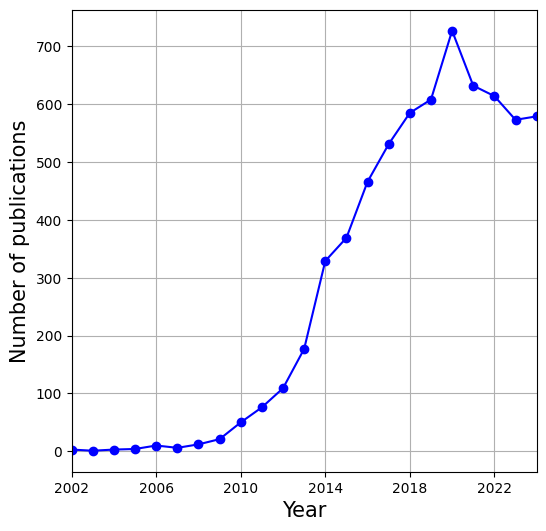

In [32]:
publication_years = data['insert_date'].astype(str).str.extract(r'^(\d{4})').astype(int).values
publication_years = pd.DataFrame(publication_years[publication_years < 2025])
publications_per_year = publication_years.value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.plot(publications_per_year.index.get_level_values(0), publications_per_year.values, marker='o', linestyle='-', color='b')

plt.xlabel('Year', size=15)
plt.xlim([publication_years.min().values[0], publication_years.max().values[0]])
plt.xticks(range(publication_years.min().values[0], publication_years.max().values[0], 4))
plt.ylabel('Number of publications', size=15)

plt.grid(True)

plt.savefig('../data/output/publications_per_year.pdf')

plt.show()

# Text preprocessing

In [33]:
# Concatenate text columns

df = data[text_cols].copy()
df['text'] = df['title'] + ' ' + df['abstract'] + ' ' + df['index_terms']
df.head()

,title,index_terms,abstract,text
0,1 5 kv 1 5 kw high voltage ratio bidirectional...,multilevel converters vacuum systems moon elem...,modular multilevel gan based isolated dc dc co...,1 5 kv 1 5 kw high voltage ratio bidirectional...
1,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,a modular multilevel llc converter suitable fo...,1 kv input 1 mhz gan modular multilevel llc co...
2,1 mw full bridge mmc for high current low volt...,low voltage modular multilevel converter full ...,a full bridge modular multilevel converter mmc...,1 mw full bridge mmc for high current low volt...
3,10 kv reverse conducting integrated gate commu...,transmission power high voltage direct current...,high voltage direct current power transmission...,10 kv reverse conducting integrated gate commu...
4,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,20 mw level offshore wind power converter base...


In [34]:
# Eliminate short words
min_word_len = 1
df['text'] = df['text'].str.split(' ').apply(lambda x: [word for word in x if len(word) > min_word_len]).apply(lambda x: ' '.join(x))
df['text']

0       kv kw high voltage ratio bidirectional dc dc c...
1       kv input mhz gan modular multilevel llc conver...
2       mw full bridge mmc for high current low voltag...
3       10 kv reverse conducting integrated gate commu...
4       20 mw level offshore wind power converter base...
                              ...                        
6628    zero tracking error nearest level modulation f...
6629    zero voltage ride through capability of transf...
6630    zero voltage switching double wing multilevel ...
6631    zpuc new configuration of single dc source for...
6632    zpuc9 mmc an increased voltage level modular m...
Name: text, Length: 6633, dtype: object

In [35]:
# Apply text preprocessing
words2remove = []
df['text'] = df['text'].apply(lambda x: preprocess_text(x, words2remove))
df.head()

,title,index_terms,abstract,text
0,1 5 kv 1 5 kw high voltage ratio bidirectional...,multilevel converters vacuum systems moon elem...,modular multilevel gan based isolated dc dc co...,kv kw high voltage ratio bidirectional dc dc c...
1,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,a modular multilevel llc converter suitable fo...,kv input mhz gan modular multilevel llc conver...
2,1 mw full bridge mmc for high current low volt...,low voltage modular multilevel converter full ...,a full bridge modular multilevel converter mmc...,mw full bridge mmc high current low voltage v ...
3,10 kv reverse conducting integrated gate commu...,transmission power high voltage direct current...,high voltage direct current power transmission...,kv reverse conducting integrated gate commutat...
4,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,mw level offshore wind power converter based s...


In [36]:
# Save df
save_data = True
if save_data:
    df.to_csv('../data/input/api/data_cleaned.csv', index=False)

# Word cloud

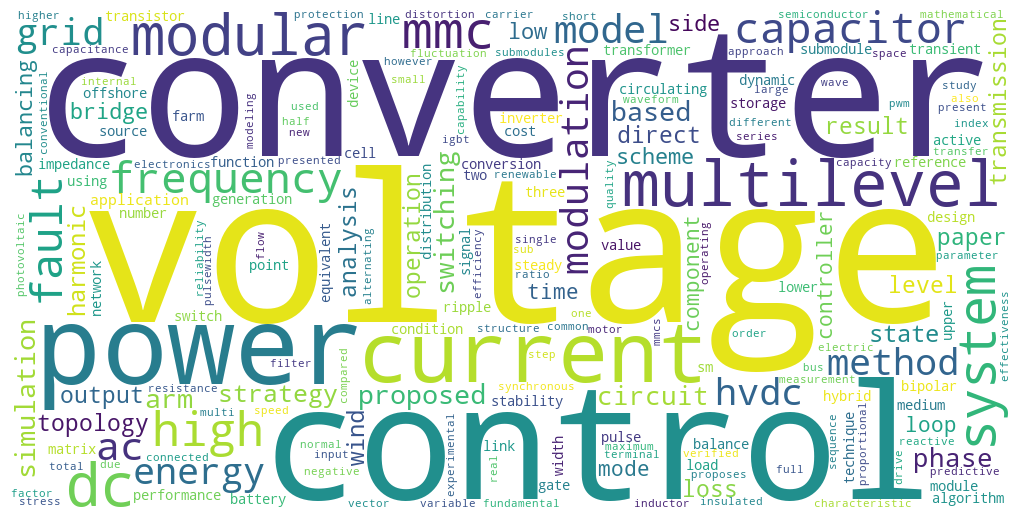

In [37]:
text = ' '.join(df['text'].str.split(' ').explode())
word_cloud(text, save_figure='word_cloud_cluster')

# Vectorization

Tf idf

In [38]:
df_vectorized = df.copy()

In [39]:
vocabulary = ' '.join(df['text']).split(' ')
len(set(vocabulary))*11//10

13018

In [40]:
# Extraer unigramas
vectorizer_unigrams = TfidfVectorizer(ngram_range=(1, 1))
X_unigrams = vectorizer_unigrams.fit_transform(df['text'])
unigram_vocab = set(vectorizer_unigrams.get_feature_names_out())

# Extraer bigramas, limitando la cantidad
max_features = len(unigram_vocab) * 3 // 10
vectorizer_bigrams = TfidfVectorizer(ngram_range=(2, 2), max_features=max_features)
X_bigrams = vectorizer_bigrams.fit_transform(df['text'])
bigram_vocab = set(vectorizer_bigrams.get_feature_names_out())

# Combinar vocabularios
combined_vocab = list(unigram_vocab) + list(bigram_vocab)

# Vectorizador final usando el vocabulario combinado
vectorizer = TfidfVectorizer(vocabulary=combined_vocab)
X_vectorized = vectorizer.fit_transform(df['text'])
words = vectorizer.get_feature_names_out()

# DataFrame final
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

In [41]:
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=len(set(vocabulary))*15//10) # No sense to use ngrams, as the frequency of appearance decays rapidly
# X_vectorized = vectorizer.fit_transform(df['text'])
# words = vectorizer.get_feature_names_out()
# df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

# Save vectorizer
joblib.dump(vectorizer, '../models/vectorizer.pkl')

['../models/vectorizer.pkl']

In [42]:
df_vectorized.columns.str.split(' ').to_series().apply(len).value_counts()

1    11812
2     3543
Name: count, dtype: int64

In [43]:
df_vectorized.columns

Index(['soc', 'niche', 'analyzation', 'dnn', 'convergence', 'sunan',
       'afterwards', 'countermeasure', 'pps', 'eexperimental',
       ...
       'input multiple', 'inner current', 'sm capacitor', 'machine drive',
       'flow voltage', 'harmonic content', 'dc cable', 'vehicle charging',
       'multiterminal hvdc', 'topology paper'],
      dtype='object', length=15355)

In [44]:
len(words), len(vocabulary)

(15355, 1379456)

In [45]:
len(set(words)), len(set(vocabulary))

(15355, 11835)

In [46]:
len(set(words) - set(vocabulary))

3543

In [47]:
len(set(vocabulary) - set(words))
set(vocabulary) - set(words)

{'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'z'}

In [48]:
# Vocabulary sorted by Tfidf score
df_vectorized.sum().sort_values()

topology paper               0.000000
operation mmc                0.000000
particle swarm               0.000000
simulation experimental      0.000000
dc network                   0.000000
                              ...    
current                    432.246798
power                      449.152020
control                    541.121766
converter                  548.667912
voltage                    762.302380
Length: 15355, dtype: float64

In [49]:
# Vocabulary sorted by appearance frequency
(df_vectorized != 0).sum().sort_values()

topology paper            0
achieve high              0
ride capability           0
battery storage           0
proposed protection       0
                       ... 
current                5895
voltage                6419
multilevel             6633
converter              6633
modular                6633
Length: 15355, dtype: int64

In [50]:
# Save df_vectorized
save_data = True
if save_data:
    df_vectorized.to_csv('../data/output/df_vectorized.csv', index=False)